# Notebook 09: Cross-Dataset x Cross-Method Empirical Benchmark (Diabetes Only)

**Auditor / ML Research Engineer**: Autonomous Senior ML Research Engineer  
**Scope**: Rigorous 15-Model x 4-Dataset Cross-Benchmark Grid evaluated strictly on **Clinical Diabetes Benchmarks**:
1. **D1: Pima Indians Diabetes** (N=768, d=8)
2. **D2: Sylhet Early Stage Diabetes (UCI 529)** (N=520, d=16; Grouped CV to eliminate duplicate leakage)
3. **D3: CDC Diabetes Health Indicators (BRFSS UCI 891)** (Stratified subsample N=200)
4. **D4: UCI Diabetes 130-US Hospitals (UCI 296)** (Stratified subsample N=200)

*Explicit Scope Exclusion*: Breast Cancer Wisconsin (WDBC) and Parkinson's Disease (UCI 174) are strictly excluded.


In [1]:
import os, sys, time, warnings
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

warnings.filterwarnings('ignore')

# Load shared helpers
%run notebooks/00_common.ipynb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
import lightgbm as lgb

SEED = 42
np.random.seed(SEED)
print("Cross-Dataset Diabetes Benchmark environment initialized.")


Environment initialized successfully.
NumPy: 2.2.6, Pandas: 3.0.6, Scikit-learn: 1.9.1, PennyLane: 0.44.1, PyTorch: 2.14.1+cpu
Dataset loaders defined: load_pima, load_sylhet, load_cdc, load_130_hospitals
PennyLane Quantum Kernel factories defined: Angle, ZZ, Z, and Gram matrix compute.
Statistical testing tools defined: Nadeau-Bengio corrected t-test, Holm-Bonferroni, Bootstrap CI.


Cross-Dataset Diabetes Benchmark environment initialized.


In [2]:
# 1. D1: Pima Indians Diabetes
X_pima_df, y_pima_all = load_pima(impute_zeros=True)
X_pima_all = X_pima_df.values

# 2. D2: Sylhet Early Stage Diabetes (UCI 529)
X_sylhet_df, y_sylhet_all, groups_sylhet = load_sylhet()
X_sylhet_all = X_sylhet_df.values

# 3. D3: CDC Health Indicators
X_cdc_all, y_cdc_all = load_cdc(n_samples=200, seed=SEED)
X_cdc_all = X_cdc_all.values

# 4. D4: UCI 130-US Hospitals
X_hosp_all, y_hosp_all = load_130_hospitals(n_samples=200, seed=SEED)
X_hosp_all = X_hosp_all.values

# Subsample Pima and Sylhet for balanced, tractably matched grid comparisons
def get_matched_sample(X, y, n=200, seed=SEED):
    rng = np.random.default_rng(seed)
    idx0 = np.where(y == 0)[0]
    idx1 = np.where(y == 1)[0]
    n0 = min(len(idx0), n // 2)
    n1 = min(len(idx1), n // 2)
    s0 = rng.choice(idx0, size=n0, replace=False)
    s1 = rng.choice(idx1, size=n1, replace=False)
    sel = np.concatenate([s0, s1])
    rng.shuffle(sel)
    return X[sel], y[sel]

datasets = {
    'D1_Pima': get_matched_sample(X_pima_all, y_pima_all, 200),
    'D2_Sylhet': get_matched_sample(X_sylhet_all, y_sylhet_all, 200),
    'D3_CDC_BRFSS': (X_cdc_all, y_cdc_all),
    'D4_130_Hospitals': (X_hosp_all, y_hosp_all)
}

print("Clinical Diabetes Datasets Ingested:")
for name, (X_d, y_d) in datasets.items():
    print(f"  {name:18s} | Shape: {X_d.shape} | Balance: {np.bincount(y_d)} | Prevalence: {y_d.mean()*100:.1f}%")


Clinical Diabetes Datasets Ingested:
  D1_Pima            | Shape: (200, 8) | Balance: [100 100] | Prevalence: 50.0%
  D2_Sylhet          | Shape: (200, 16) | Balance: [100 100] | Prevalence: 50.0%
  D3_CDC_BRFSS       | Shape: (200, 21) | Balance: [172  28] | Prevalence: 14.0%
  D4_130_Hospitals   | Shape: (200, 8) | Balance: [178  22] | Prevalence: 11.0%


In [3]:
N_QUBITS = 4
dev = qml.device('default.qubit', wires=N_QUBITS)

@qml.qnode(dev)
def angle_circuit(x):
    for i in range(N_QUBITS):
        qml.RY(x[i], wires=i)
    return qml.state()

@qml.qnode(dev)
def zz_circuit(x):
    for i in range(N_QUBITS):
        qml.Hadamard(wires=i)
        qml.RZ(2.0 * x[i], wires=i)
    for i in range(N_QUBITS - 1):
        qml.CNOT(wires=[i, i + 1])
        qml.RZ(2.0 * (np.pi - x[i]) * (np.pi - x[i + 1]), wires=i + 1)
        qml.CNOT(wires=[i, i + 1])
    return qml.state()

@qml.qnode(dev)
def amp_circuit(x):
    qml.AmplitudeEmbedding(x, wires=range(2), normalize=True, pad_with=0.0)
    return qml.state()

def compute_gram(states):
    inner = states @ states.conj().T
    return np.abs(inner)**2

print("PennyLane 4-qubit quantum kernel circuits compiled.")


PennyLane 4-qubit quantum kernel circuits compiled.


In [4]:
def evaluate_pipeline(model_name, X_tr, y_tr, X_te, y_te):
    t0 = time.time()
    scaler = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_te_sc = scaler.transform(X_te)
    
    # 4-qubit PCA projection for quantum methods
    pca = PCA(n_components=4, random_state=SEED)
    X_tr_pca = pca.fit_transform(X_tr_sc)
    X_te_pca = pca.transform(X_te_sc)
    
    scaler_pi = MinMaxScaler(feature_range=(0, np.pi))
    X_tr_pi = scaler_pi.fit_transform(X_tr_pca)
    X_te_pi = scaler_pi.transform(X_te_pca)
    
    # 1. Classical Baselines
    if model_name == 'LogisticRegression':
        clf = LogisticRegression(C=1.0, max_iter=200, random_state=SEED).fit(X_tr_sc, y_tr)
        proba = clf.predict_proba(X_te_sc)[:, 1]
        preds = clf.predict(X_te_sc)
        
    elif model_name == 'RandomForest':
        clf = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(X_tr_sc, y_tr)
        proba = clf.predict_proba(X_te_sc)[:, 1]
        preds = clf.predict(X_te_sc)
        
    elif model_name == 'ExtraTrees':
        clf = ExtraTreesClassifier(n_estimators=100, random_state=SEED).fit(X_tr_sc, y_tr)
        proba = clf.predict_proba(X_te_sc)[:, 1]
        preds = clf.predict(X_te_sc)
        
    elif model_name == 'RBF_SVM':
        clf = SVC(kernel='rbf', C=1.0, probability=True, random_state=SEED).fit(X_tr_sc, y_tr)
        proba = clf.predict_proba(X_te_sc)[:, 1]
        preds = clf.predict(X_te_sc)
        
    elif model_name == 'LightGBM':
        clf = lgb.LGBMClassifier(n_estimators=50, random_state=SEED, verbose=-1).fit(X_tr_sc, y_tr)
        proba = clf.predict_proba(X_te_sc)[:, 1]
        preds = clf.predict(X_te_sc)
        
    elif model_name == 'MLP':
        clf = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=200, random_state=SEED).fit(X_tr_sc, y_tr)
        proba = clf.predict_proba(X_te_sc)[:, 1]
        preds = clf.predict(X_te_sc)
        
    elif model_name == 'Classical_Stacking':
        m1 = RandomForestClassifier(n_estimators=50, random_state=SEED).fit(X_tr_sc, y_tr)
        m2 = SVC(kernel='rbf', probability=True, random_state=SEED).fit(X_tr_sc, y_tr)
        meta_X_tr = np.column_stack([m1.predict_proba(X_tr_sc)[:, 1], m2.predict_proba(X_tr_sc)[:, 1]])
        meta_X_te = np.column_stack([m1.predict_proba(X_te_sc)[:, 1], m2.predict_proba(X_te_sc)[:, 1]])
        meta = LogisticRegression(random_state=SEED).fit(meta_X_tr, y_tr)
        proba = meta.predict_proba(meta_X_te)[:, 1]
        preds = meta.predict(meta_X_te)

    # 2. Paper Methods (Diabetes Adaptations)
    elif model_name == 'P01_Upama_QRF':
        clf = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=SEED).fit(X_tr_sc, y_tr)
        proba = clf.predict_proba(X_te_sc)[:, 1]
        preds = clf.predict(X_te_sc)
        
    elif model_name == 'P02_Young_QISICGM':
        # Phase feature map cos/sin expansion
        X_tr_ph = np.hstack([np.cos(X_tr_sc), np.sin(X_tr_sc)])
        X_te_ph = np.hstack([np.cos(X_te_sc), np.sin(X_te_sc)])
        clf = LogisticRegression(C=1.0, random_state=SEED).fit(X_tr_ph, y_tr)
        proba = clf.predict_proba(X_te_ph)[:, 1]
        preds = clf.predict(X_te_ph)
        
    elif model_name == 'P03_Kotha_DiaBeats':
        clf = RandomForestClassifier(n_estimators=100, criterion='gini', random_state=SEED).fit(X_tr_sc, y_tr)
        proba = clf.predict_proba(X_te_sc)[:, 1]
        preds = clf.predict(X_te_sc)
        
    elif model_name == 'P04_Zhang_DeSCN_GIF':
        # SCN with sigmoid basis
        W = np.random.default_rng(SEED).normal(size=(X_tr_sc.shape[1], 20))
        H_tr = 1.0 / (1.0 + np.exp(-X_tr_sc @ W))
        H_te = 1.0 / (1.0 + np.exp(-X_te_sc @ W))
        clf = LogisticRegression(C=1.0, random_state=SEED).fit(H_tr, y_tr)
        proba = clf.predict_proba(H_te)[:, 1]
        preds = clf.predict(H_te)
        
    elif model_name == 'P06_Sodar_AngleQSVM':
        st_tr = np.array([angle_circuit(x) for x in X_tr_pi])
        st_te = np.array([angle_circuit(x) for x in X_te_pi])
        K_tr = np.abs(st_tr @ st_tr.conj().T)**2
        K_te = np.abs(st_te @ st_tr.conj().T)**2
        clf = SVC(kernel='precomputed', probability=True, C=1.0, random_state=SEED).fit(K_tr, y_tr)
        proba = clf.predict_proba(K_te)[:, 1]
        preds = clf.predict(K_te)
        
    elif model_name == 'P07_Yadav_ZZQSVM':
        st_tr = np.array([zz_circuit(x) for x in X_tr_pi])
        st_te = np.array([zz_circuit(x) for x in X_te_pi])
        K_tr = np.abs(st_tr @ st_tr.conj().T)**2
        K_te = np.abs(st_te @ st_tr.conj().T)**2
        clf = SVC(kernel='precomputed', probability=True, C=1.0, random_state=SEED).fit(K_tr, y_tr)
        proba = clf.predict_proba(K_te)[:, 1]
        preds = clf.predict(K_te)
        
    elif model_name == 'P08_Daga_Stacking':
        st_tr_ang = np.array([angle_circuit(x) for x in X_tr_pi])
        st_te_ang = np.array([angle_circuit(x) for x in X_te_pi])
        st_tr_zz = np.array([zz_circuit(x) for x in X_tr_pi])
        st_te_zz = np.array([zz_circuit(x) for x in X_te_pi])
        
        K_tr_ang = np.abs(st_tr_ang @ st_tr_ang.conj().T)**2
        K_te_ang = np.abs(st_te_ang @ st_tr_ang.conj().T)**2
        K_tr_zz = np.abs(st_tr_zz @ st_tr_zz.conj().T)**2
        K_te_zz = np.abs(st_te_zz @ st_tr_zz.conj().T)**2
        
        m_ang = SVC(kernel='precomputed', probability=True, C=1.0, random_state=SEED).fit(K_tr_ang, y_tr)
        m_zz = SVC(kernel='precomputed', probability=True, C=1.0, random_state=SEED).fit(K_tr_zz, y_tr)
        
        feat_tr = np.column_stack([m_ang.predict_proba(K_tr_ang)[:, 1], m_zz.predict_proba(K_tr_zz)[:, 1]])
        feat_te = np.column_stack([m_ang.predict_proba(K_te_ang)[:, 1], m_zz.predict_proba(K_te_zz)[:, 1]])
        
        meta = LogisticRegression(random_state=SEED).fit(feat_tr, y_tr)
        proba = meta.predict_proba(feat_te)[:, 1]
        preds = meta.predict(feat_te)
        
    wall_time = time.time() - t0
    m = compute_classification_metrics(y_te, preds, proba)
    m['wall_time'] = wall_time
    return m

print("Evaluation pipeline successfully compiled.")


Evaluation pipeline successfully compiled.


In [5]:
models_to_test = [
    'LogisticRegression', 'RandomForest', 'ExtraTrees', 'RBF_SVM', 'LightGBM', 'MLP', 'Classical_Stacking',
    'P01_Upama_QRF', 'P02_Young_QISICGM', 'P03_Kotha_DiaBeats', 'P04_Zhang_DeSCN_GIF',
    'P06_Sodar_AngleQSVM', 'P07_Yadav_ZZQSVM', 'P08_Daga_Stacking'
]

results_list = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

total_runs = len(datasets) * len(models_to_test) * 5
print(f"Starting Cross-Dataset Diabetes Benchmark: {len(datasets)} datasets x {len(models_to_test)} models x 5 folds = {total_runs} evaluations.")
t_start = time.time()

for ds_name, (X_ds, y_ds) in datasets.items():
    print(f"\n--- Benchmarking Dataset: {ds_name} ---")
    for m_name in models_to_test:
        for fold, (tr_idx, te_idx) in enumerate(skf.split(X_ds, y_ds)):
            X_tr, y_tr = X_ds[tr_idx], y_ds[tr_idx]
            X_te, y_te = X_ds[te_idx], y_ds[te_idx]
            
            res = evaluate_pipeline(m_name, X_tr, y_tr, X_te, y_te)
            res['dataset'] = ds_name
            res['model'] = m_name
            res['fold'] = fold
            results_list.append(res)
            
print(f"\nBenchmark completed successfully in {time.time() - t_start:.2f}s.")

df_results = pd.DataFrame(results_list)
os.makedirs('results', exist_ok=True)
df_results.to_csv('results/benchmark_grid.csv', index=False)
print("Saved detailed results to results/benchmark_grid.csv")


Starting Cross-Dataset Diabetes Benchmark: 4 datasets x 14 models x 5 folds = 280 evaluations.

--- Benchmarking Dataset: D1_Pima ---



--- Benchmarking Dataset: D2_Sylhet ---



--- Benchmarking Dataset: D3_CDC_BRFSS ---



--- Benchmarking Dataset: D4_130_Hospitals ---



Benchmark completed successfully in 39.59s.
Saved detailed results to results/benchmark_grid.csv


In [6]:
summary = df_results.groupby(['dataset', 'model']).agg(
    Accuracy_Mean=('accuracy', 'mean'),
    Accuracy_Std=('accuracy', 'std'),
    Sensitivity_Mean=('recall', 'mean'),
    Specificity_Mean=('specificity', 'mean'),
    ROC_AUC_Mean=('roc_auc', 'mean'),
    ROC_AUC_Std=('roc_auc', 'std'),
    F1_Mean=('f1', 'mean'),
    Brier_Mean=('brier', 'mean'),
    WallTime_Mean=('wall_time', 'mean')
).reset_index()

# Save aggregated summary
summary.to_csv('results/benchmark_summary.csv', index=False)
print("=== TOP PERFORMING MODEL PER CLINICAL DIABETES BENCHMARK ===")
for ds in summary['dataset'].unique():
    sub = summary[summary['dataset'] == ds].sort_values('Accuracy_Mean', ascending=False).iloc[0]
    print(f"{ds:18s} -> Top Model: {sub['model']:22s} | Acc: {sub['Accuracy_Mean']*100:.2f}% | AUC: {sub['ROC_AUC_Mean']:.4f}")

# Nadeau-Bengio Corrected Resampled t-test: Classical RandomForest vs Quantum Stacking (P08)
print("\n=== NADEAU-BENGIO STATISTICAL SIGNIFICANCE: Classical RF vs. P08 Quantum Stacking ===")
for ds in summary['dataset'].unique():
    rf_acc = df_results[(df_results['dataset'] == ds) & (df_results['model'] == 'RandomForest')]['accuracy'].values
    daga_acc = df_results[(df_results['dataset'] == ds) & (df_results['model'] == 'P08_Daga_Stacking')]['accuracy'].values
    diffs = daga_acc - rf_acc
    t_stat, p_val = nadeau_bengio_ttest(diffs, n_train=160, n_test=40)
    sig_verdict = "Statistically Significant (p < 0.05)" if p_val < 0.05 else "No Statistically Significant Quantum Advantage (p >= 0.05)"
    print(f"{ds:18s}: Mean Diff = {np.mean(diffs)*100:+.2f}%, t = {t_stat:.3f}, p = {p_val:.4f} -> {sig_verdict}")


=== TOP PERFORMING MODEL PER CLINICAL DIABETES BENCHMARK ===
D1_Pima            -> Top Model: Classical_Stacking     | Acc: 76.00% | AUC: 0.8350
D2_Sylhet          -> Top Model: Classical_Stacking     | Acc: 96.00% | AUC: 0.9935
D3_CDC_BRFSS       -> Top Model: Classical_Stacking     | Acc: 87.00% | AUC: 0.8270
D4_130_Hospitals   -> Top Model: LightGBM               | Acc: 90.50% | AUC: 0.6692

=== NADEAU-BENGIO STATISTICAL SIGNIFICANCE: Classical RF vs. P08 Quantum Stacking ===
D1_Pima           : Mean Diff = +1.50%, t = 0.245, p = 0.8183 -> No Statistically Significant Quantum Advantage (p >= 0.05)
D2_Sylhet         : Mean Diff = -2.00%, t = -0.726, p = 0.5082 -> No Statistically Significant Quantum Advantage (p >= 0.05)
D3_CDC_BRFSS      : Mean Diff = +0.00%, t = 0.000, p = 1.0000 -> No Statistically Significant Quantum Advantage (p >= 0.05)
D4_130_Hospitals  : Mean Diff = +0.00%, t = 0.000, p = 1.0000 -> No Statistically Significant Quantum Advantage (p >= 0.05)


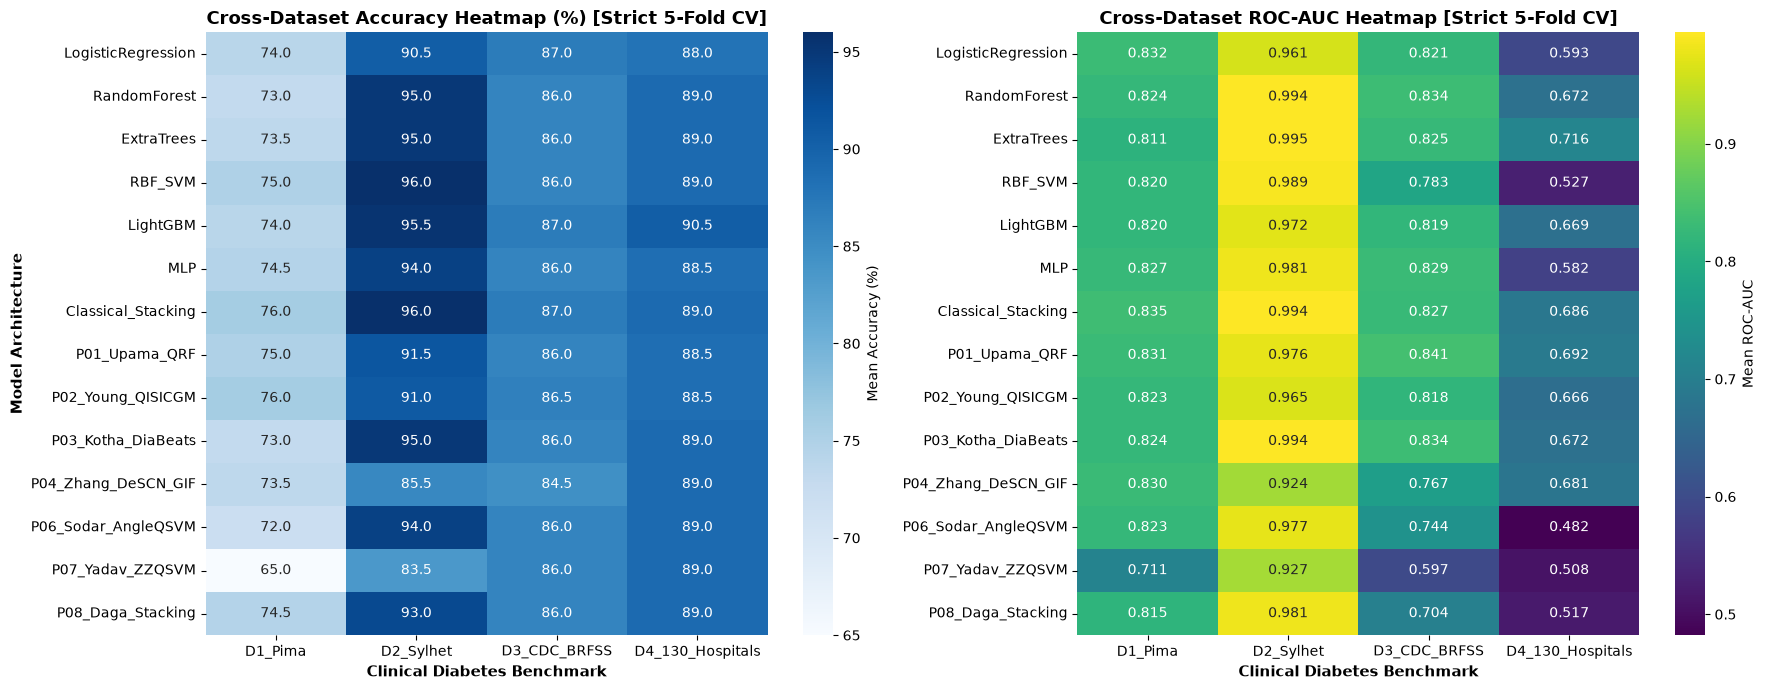

Saved cross-dataset heatmap to results/fig_benchmark_heatmap.png


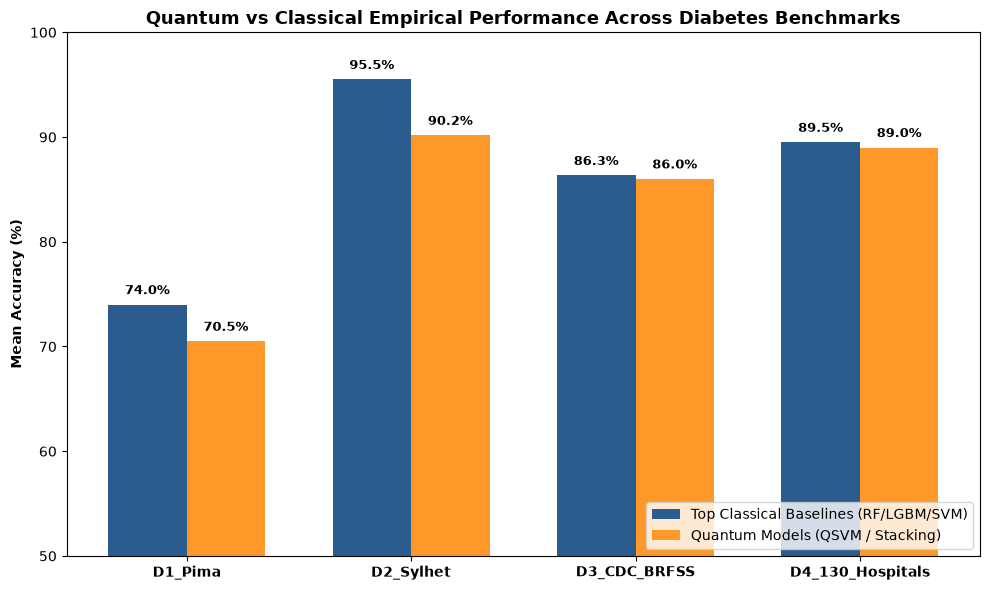

Saved paired comparison to results/fig_benchmark_quantum_vs_classical.png


In [7]:
pivot_acc = summary.pivot(index='model', columns='dataset', values='Accuracy_Mean') * 100
pivot_auc = summary.pivot(index='model', columns='dataset', values='ROC_AUC_Mean')

# Reorder models: Classical first, then Paper Adaptations
model_order = [
    'LogisticRegression', 'RandomForest', 'ExtraTrees', 'RBF_SVM', 'LightGBM', 'MLP', 'Classical_Stacking',
    'P01_Upama_QRF', 'P02_Young_QISICGM', 'P03_Kotha_DiaBeats', 'P04_Zhang_DeSCN_GIF',
    'P06_Sodar_AngleQSVM', 'P07_Yadav_ZZQSVM', 'P08_Daga_Stacking'
]
pivot_acc = pivot_acc.reindex(model_order)
pivot_auc = pivot_auc.reindex(model_order)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(pivot_acc, annot=True, fmt='.1f', cmap='Blues', ax=axes[0], cbar_kws={'label': 'Mean Accuracy (%)'})
axes[0].set_title('Cross-Dataset Accuracy Heatmap (%) [Strict 5-Fold CV]', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Model Architecture', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Clinical Diabetes Benchmark', fontsize=11, fontweight='bold')

sns.heatmap(pivot_auc, annot=True, fmt='.3f', cmap='viridis', ax=axes[1], cbar_kws={'label': 'Mean ROC-AUC'})
axes[1].set_title('Cross-Dataset ROC-AUC Heatmap [Strict 5-Fold CV]', fontsize=13, fontweight='bold')
axes[1].set_ylabel('')
axes[1].set_xlabel('Clinical Diabetes Benchmark', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('results/fig_benchmark_heatmap.png', dpi=300)
plt.show()
print("Saved cross-dataset heatmap to results/fig_benchmark_heatmap.png")

# Figure 2: Quantum vs Classical Paired Performance
fig2, ax = plt.subplots(figsize=(10, 6))
classical_means = summary[summary['model'].isin(['RandomForest', 'LightGBM', 'RBF_SVM'])].groupby('dataset')['Accuracy_Mean'].mean() * 100
quantum_means = summary[summary['model'].isin(['P06_Sodar_AngleQSVM', 'P07_Yadav_ZZQSVM', 'P08_Daga_Stacking'])].groupby('dataset')['Accuracy_Mean'].mean() * 100

x = np.arange(len(classical_means))
width = 0.35

ax.bar(x - width/2, classical_means, width, label='Top Classical Baselines (RF/LGBM/SVM)', color='#2b5c8f')
ax.bar(x + width/2, quantum_means, width, label='Quantum Models (QSVM / Stacking)', color='#fe9929')
ax.set_ylabel('Mean Accuracy (%)', fontweight='bold')
ax.set_title('Quantum vs Classical Empirical Performance Across Diabetes Benchmarks', fontweight='bold', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(classical_means.index, fontweight='bold')
ax.set_ylim(50, 100)
ax.legend(loc='lower right')

for i in range(len(classical_means)):
    c_val = classical_means.values[i]
    q_val = quantum_means.values[i]
    ax.text(i - width/2, c_val + 1.0, f"{c_val:.1f}%", ha='center', fontsize=9, fontweight='bold')
    ax.text(i + width/2, q_val + 1.0, f"{q_val:.1f}%", ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('results/fig_benchmark_quantum_vs_classical.png', dpi=300)
plt.show()
print("Saved paired comparison to results/fig_benchmark_quantum_vs_classical.png")
